# Dashboard Royale: analysis and evidence
Original checks, machine investigation, remaining challenge analysis and the 30-day decision model are together here.

**Read in order:** original checks → luck/downtime investigation → complete analysis below. The final section exports the data for the three-page Streamlit app. All monetary findings use synthetic January–June 2025 data. The decision horizon is July 1–30, 2025.

**Chosen objective:** maximize expected 30-day incremental benefit after costs. Effect assumptions are not causal estimates. The limited shortlist is compared against keeping the budget. Original check outputs are retained.


In [0]:
daily = spark.table("workspace.default.prepared_daily_view")

print(f"Rows: {daily.count():,}")
print(f"Columns: {len(daily.columns)}")

display(daily.limit(5))

Rows: 56,110
Columns: 44


machine_id,gaming_date,month,local_weekday,is_weekend,federal_holiday,events_active,zone_id,zone_name,bank_id,location_id,config_id,theme,configured_rtp,volatility_class,manufacturer,lease_class,active,meter_status,available_hours,occupied_hours,availability_ratio,occupancy_ratio,paid_spins,coin_in_usd,payout_usd,house_win_usd,theo_usd,observed_hold,theo_hold,luck_residual_usd,carded_coin_in_usd,carded_share,faults_opened,zone_entries_observed,zone_counter_coverage_hours,lease_cost_usd,service_cost_usd,power_cost_usd,repair_cost_usd,contribution_after_supplied_costs_usd,lag_coin_in_7d_mean_usd,lag_downtime_7d_hours,lag_house_win_28d_usd
M-1001,2025-01-01,2025-01,Wed,false,New Year's Day,null,Z-ENT,Main Entrance,B-01,L-01-6,G-PEN89,Prairie Thunder,0.89000000,medium,Halcyon,leased_fixed,true,reported,24.0,10.548055555555555,1.0,0.43950231481481483,6253,5268.40,4344.40,924.00,579.5240,0.17538531622503986,0.11,344.4760,4388.80,0.8330422898792802,0,1999,23.0,45.00,6.00,6.00,0.00,867.00,null,null,null
M-1001,2025-01-02,2025-01,Thu,false,null,null,Z-ENT,Main Entrance,B-01,L-01-6,G-PEN89,Prairie Thunder,0.89000000,medium,Halcyon,leased_fixed,true,reported,24.0,10.231111111111112,1.0,0.4262962962962963,6275,4314.80,3569.20,745.60,474.6280,0.17280059330675812,0.11,270.9720,2938.40,0.6810049133215909,0,2530,24.0,45.00,6.00,6.00,0.00,688.60,5268.4,0.0,924.0
M-1001,2025-01-03,2025-01,Fri,false,null,null,Z-ENT,Main Entrance,B-01,L-01-6,G-PEN89,Prairie Thunder,0.89000000,medium,Halcyon,leased_fixed,true,reported,24.0,14.368333333333334,1.0,0.5986805555555555,9404,4945.60,4198.60,747.00,544.0160,0.15104335166612748,0.11,202.9840,3617.20,0.7313976059527661,0,3145,24.0,45.00,6.00,6.00,0.00,690.00,4791.6,0.0,1669.6
M-1001,2025-01-04,2025-01,Sat,true,null,null,Z-ENT,Main Entrance,B-01,L-01-6,G-PEN89,Prairie Thunder,0.89000000,medium,Halcyon,leased_fixed,true,reported,24.0,11.64638888888889,1.0,0.4852662037037037,7313,6137.20,5172.40,964.80,675.0920,0.1572052401746725,0.11,289.7080,4367.20,0.7115948641074106,0,3560,24.0,45.00,6.00,6.00,0.00,907.80,4842.933333333333,0.0,2416.6
M-1001,2025-01-05,2025-01,Sun,true,null,null,Z-ENT,Main Entrance,B-01,L-01-6,G-PEN89,Prairie Thunder,0.89000000,medium,Halcyon,leased_fixed,true,reported,24.0,13.17361111111111,1.0,0.5489004629629629,8381,6702.80,5506.60,1196.20,737.3080,0.1784627319926001,0.11,458.8920,5863.20,0.8747389150802649,0,2865,24.0,45.00,6.00,6.00,0.00,1139.20,5166.5,0.0,3381.3999999999996


In [0]:
from pyspark.sql import functions as F

# Check dates and number of machines
display(daily.agg(
    F.min("gaming_date").alias("first_date"),
    F.max("gaming_date").alias("last_date"),
    F.countDistinct("gaming_date").alias("days"),
    F.countDistinct("machine_id").alias("machines")
))

# Each machine should have only one row per day
duplicates = (
    daily.groupBy("machine_id", "gaming_date")
    .count()
    .filter(F.col("count") > 1)
)
print("Duplicate machine-day groups:", duplicates.count())

# Check days when machines were active or inactive
display(daily.groupBy("active").count())

first_date,last_date,days,machines
2025-01-01,2025-06-30,181,310


Duplicate machine-day groups: 0


active,count
true,55092
false,1018


In [0]:
from pyspark.sql import functions as F

# Keep active machine-days; the original table stays intact.
active_daily = daily.filter(F.col("active") == True)

# Identify rows with missing inputs or results.
required = [
    "coin_in_usd", "payout_usd", "house_win_usd",
    "configured_rtp", "theo_usd"
]

missing = F.lit(False)
for column in required:
    missing = missing | F.col(column).isNull()

# Recalculate the two money figures.
expected_house_win = F.col("coin_in_usd") - F.col("payout_usd")

# Theo is stored to four decimal places.
expected_theo = F.round(
    F.col("coin_in_usd") * (1 - F.col("configured_rtp")), 4
)

checks = {
    "Rows with missing values": missing,
    "House win mismatches":
        F.col("house_win_usd") != expected_house_win,
    "Theo mismatches":
        F.col("theo_usd") != expected_theo
}

# Count rows flagged by each check.
results = active_daily.agg(*[
    F.sum(F.when(condition, 1).otherwise(0)).alias(name)
    for name, condition in checks.items()
]).first()

for name, count in results.asDict().items():
    print(f"{name}: {count:,}")

Rows with missing values: 0
House win mismatches: 0
Theo mismatches: 0


In [0]:
totals = active_daily.agg(
    F.sum("coin_in_usd").alias("wagers"),
    F.sum("payout_usd").alias("payouts"),
    F.sum("house_win_usd").alias("house_win"),
    F.sum("theo_usd").alias("theo")
).first()

for label, column in [
    ("Total wagers", "wagers"),
    ("Total payouts", "payouts"),
    ("Actual casino earnings before costs", "house_win"),
    ("Expected casino earnings before costs", "theo")
]:
    print(f"{label}: ${totals[column]:,.2f}")

if totals["wagers"] > 0:
    hold = totals["house_win"] / totals["wagers"]
    print(f"Overall hold: {hold:.2%}")

Total wagers: $248,905,219.25
Total payouts: $225,267,064.15
Actual casino earnings before costs: $23,638,155.10
Expected casino earnings before costs: $23,545,364.48
Overall hold: 9.50%


In [0]:
# Add up earnings for each machine, then select the lowest 10.
bottom10 = (
    active_daily
    .groupBy("machine_id")
    .agg(
        F.sum("house_win_usd").alias("total_house_win_usd")
    )
    .orderBy(F.col("total_house_win_usd").asc(), "machine_id")
    .limit(10)
)

display(bottom10)

machine_id,total_house_win_usd
M-5076,3573.25
M-1158,15796.25
M-1120,16355.00
M-1118,20050.00
M-1238,24932.75
M-1181,26977.00
M-1035,30303.50
M-1179,30393.75
M-1017,31939.50
M-1265,32071.00


Databricks visualization. Run in Databricks to view.

# Verified investigation results
These two charts were generated in Databricks by the successful `Luck and Downtime Lab` run. They are embedded here so the results are visible together with the original checks.

- **M-1158:** $15,796.25 actual versus $51,961 expected; only 3.01 hours of downtime. The payout pattern deserves review, not a diagnosis of malfunction or wrongdoing.
- **M-1118 and M-1120:** retired before June ended, so exclude them from July replacement targets.
- **M-1065:** approximately 81.11 hours unavailable, the largest downtime among machines present at period end.

These are saved results. The machine and scenario controls apply to the reproducible analysis below when you select **Run all**; the two saved overview images retain their original context.


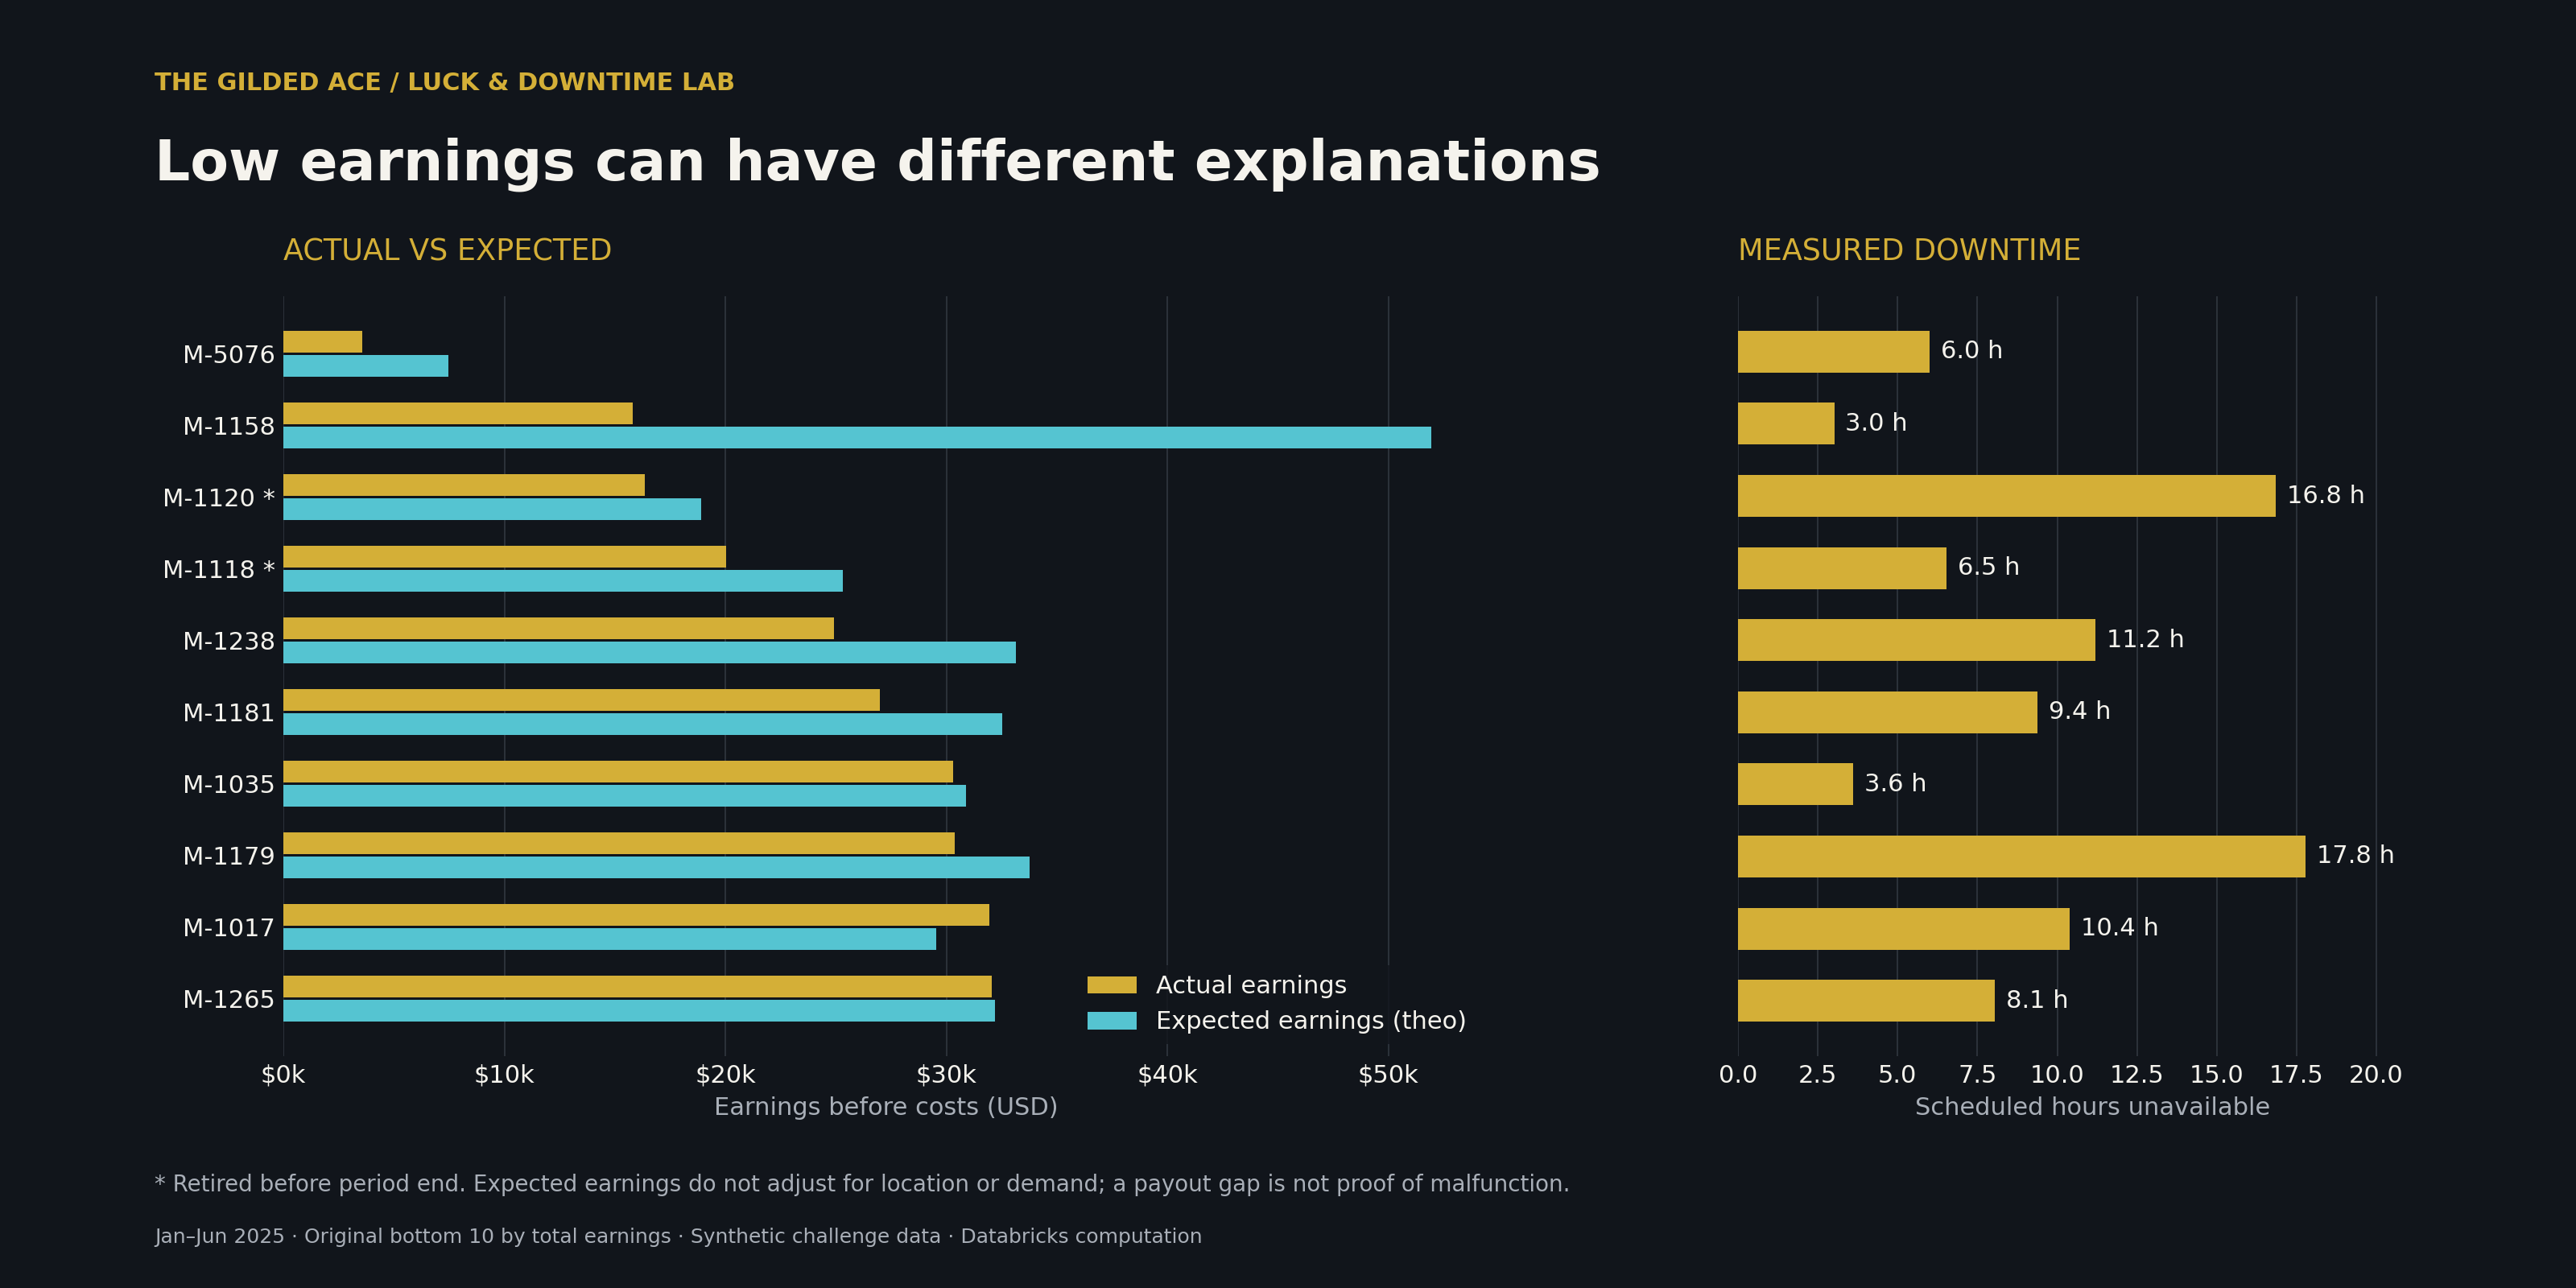

In [0]:
from IPython.display import Image, display as show_image
show_image(Image(filename='/Volumes/workspace/default/dashboard_royale_source/analysis_exports/luck_vs_downtime.png'))


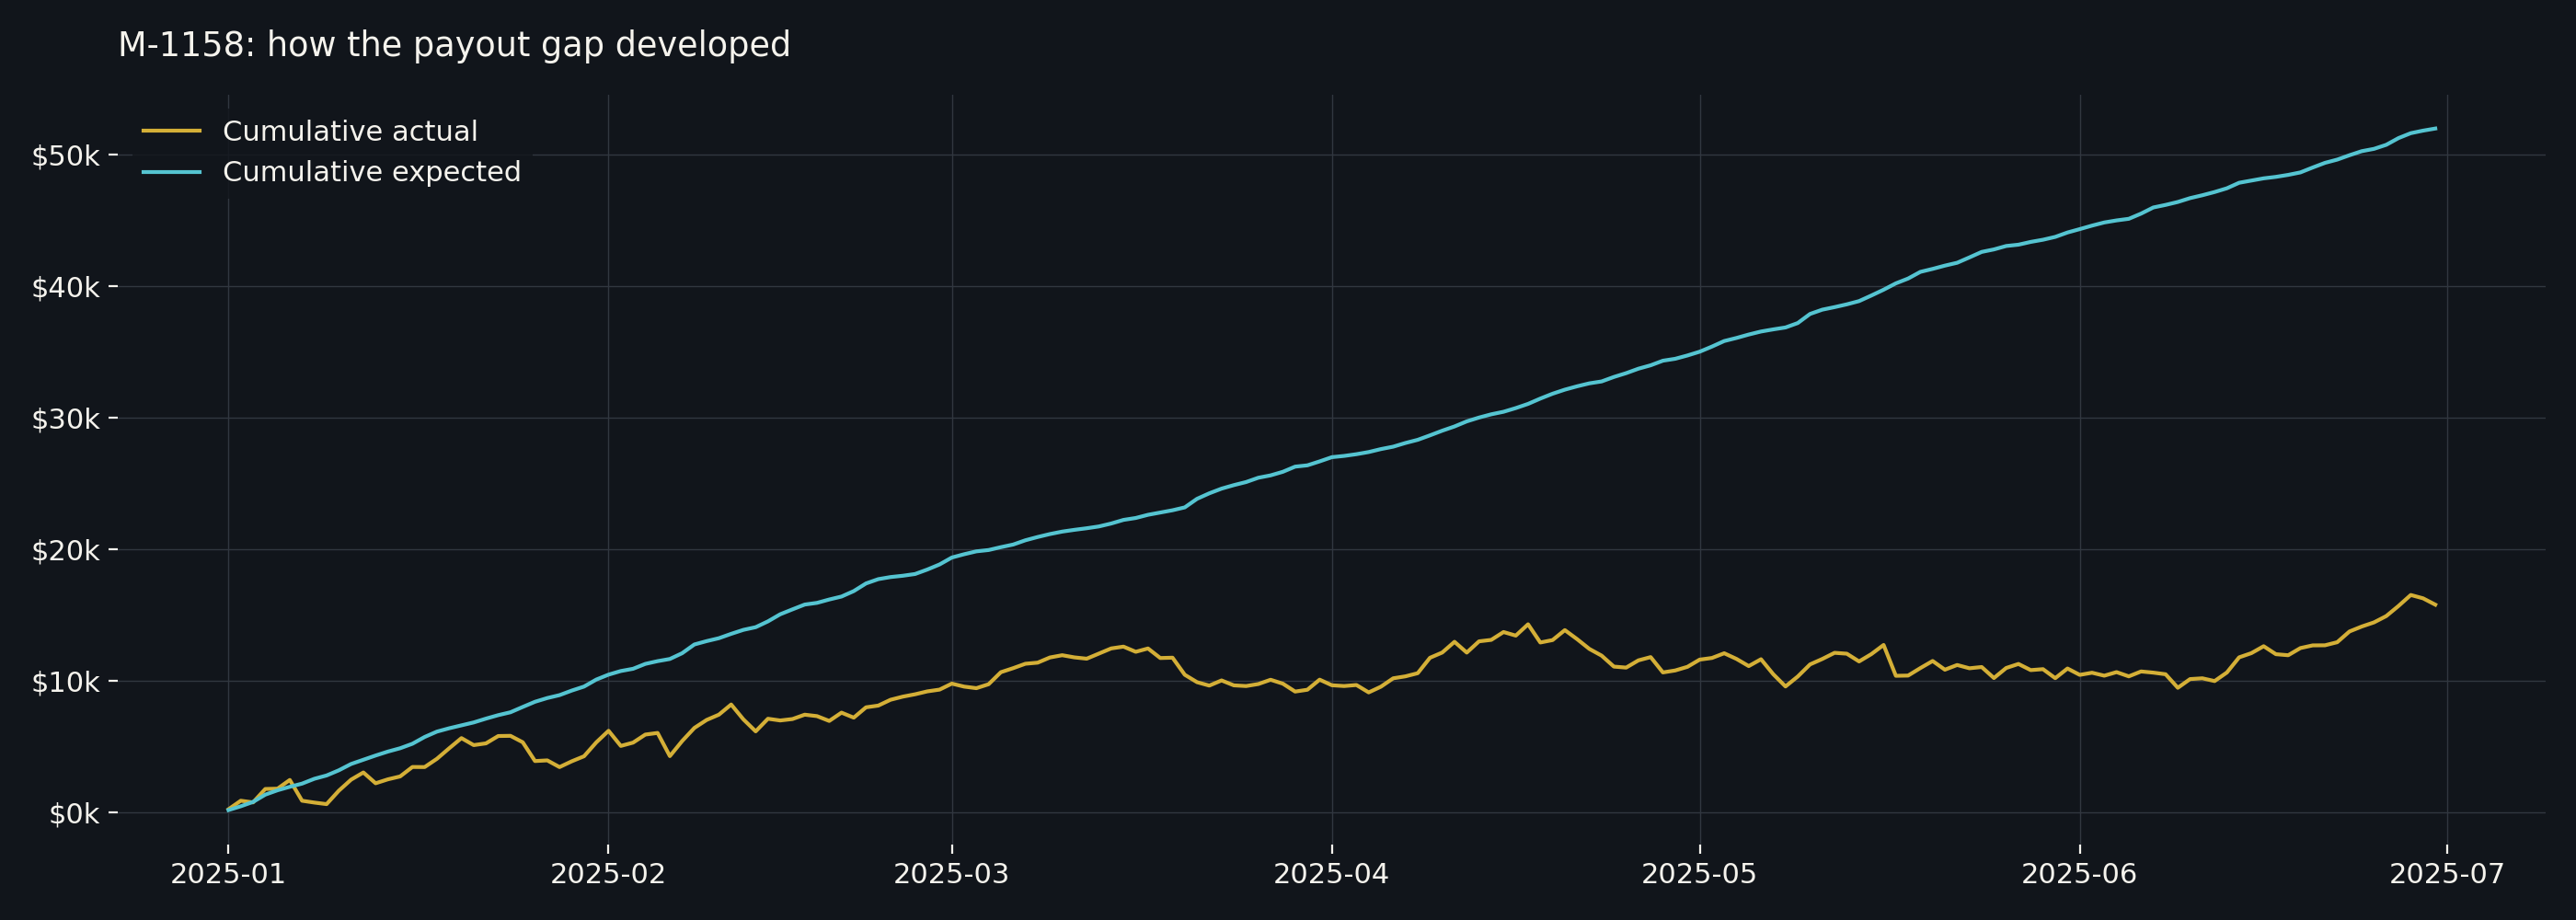

In [0]:
from IPython.display import Image, display as show_image
show_image(Image(filename='/Volumes/workspace/default/dashboard_royale_source/analysis_exports/M-1158_cumulative_earnings.png'))


# The Gilded Ace — Luck & Downtime Lab
Investigate before replacing. Compare actual earnings, expected earnings and unavailable time, then explore a historical downtime-recovery scenario.

**Learning guide:** Actual earnings = wagers minus payouts. Expected earnings (theo) use the configured payout rate. Their difference is a payout deviation, not proof that luck alone caused it. Downtime is scheduled time minus available time. Inactive days are excluded.

All casino data is synthetic. Period: January 1–June 30, 2025. Change the machine and scenario controls, then **Run all** to refresh this notebook.


In [0]:
from pyspark.sql import functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
import json
import html

VOLUME = '/Volumes/workspace/default/dashboard_royale_source'
EXPORT = Path(VOLUME) / 'analysis_exports'
EXPORT.mkdir(exist_ok=True)
daily = spark.table('workspace.default.prepared_daily_view')
meters = spark.read.parquet(f'{VOLUME}/machine_day.parquet')
machines = spark.read.parquet(f'{VOLUME}/machines.parquet')
math = spark.read.parquet(f'{VOLUME}/game_math.parquet')
operations = spark.read.parquet(f'{VOLUME}/operations.parquet')
for name, data in [('royale_daily',daily), ('royale_meters',meters),
                   ('royale_machines',machines), ('royale_math',math)]:
    data.createOrReplaceTempView(name)


## 1. Build a fairer comparison
Raw meters supply actual scheduled seconds, including shortened days and partial periods. We retain all 310 machines so we can compare the manager's bottom ten with machines that had more downtime.

**Checks:** one row per machine-day, valid scheduled/available seconds, unique game configurations, and reconciliation with your prepared table.


In [0]:
assert meters.groupBy('machine_id','gaming_date').count().filter('count > 1').count() == 0
assert math.groupBy('config_id').count().filter('count > 1').count() == 0
assert machines.groupBy('machine_id').count().filter('count > 1').count() == 0
assert meters.filter('active AND (available_seconds < 0 OR available_seconds > scheduled_seconds)').count() == 0
assert meters.filter('active').join(math, 'config_id', 'left_anti').count() == 0
prepared_total = daily.filter('active').agg(F.sum('house_win_usd')).first()[0]
raw_total = meters.filter('active').agg(F.sum('house_win_cents')).first()[0]
assert abs(float(prepared_total) - raw_total / 100) < 0.001

diagnostics = spark.sql('''
WITH a AS (
 SELECT d.machine_id, count(*) AS active_days,
        min(d.gaming_date) AS first_active_date, max(d.gaming_date) AS last_active_date,
        sum(d.house_win_cents)/100.0 AS actual_usd,
        sum(d.theo_cents)/100.0 AS expected_usd,
        sum(d.coin_in_cents)/100.0 AS wagers_usd,
        sum(d.scheduled_seconds)/3600.0 AS scheduled_hours,
        sum(d.available_seconds)/3600.0 AS available_hours,
        sum(d.scheduled_seconds-d.available_seconds)/3600.0 AS downtime_hours,
        sqrt(sum(d.sum_bet_squared * g.payout_multiplier_variance))/100.0 AS payout_sd_usd
 FROM royale_meters d JOIN royale_math g USING(config_id)
 WHERE d.active AND d.gaming_date BETWEEN DATE '2025-01-01' AND DATE '2025-06-30'
 GROUP BY d.machine_id
)
SELECT a.*, m.manufacturer, m.theme, m.install_date, m.retire_date,
       (m.install_date <= DATE '2025-06-30' AND
        (m.retire_date IS NULL OR m.retire_date > DATE '2025-06-30')) AS on_floor_at_period_end,
       actual_usd / active_days AS actual_per_active_day,
       expected_usd / active_days AS expected_per_active_day,
       actual_usd - expected_usd AS payout_deviation_usd,
       available_hours / nullif(scheduled_hours,0) AS availability,
       expected_usd / nullif(available_hours,0) AS expected_per_available_hour,
       (actual_usd-expected_usd) / nullif(payout_sd_usd,0) AS standardized_payout_deviation,
       downtime_hours * expected_usd / nullif(available_hours,0) AS historical_downtime_theo_proxy_usd
FROM a JOIN royale_machines m USING(machine_id)
''')

pdf = diagnostics.toPandas()
numeric = ['actual_usd','expected_usd','wagers_usd','scheduled_hours','available_hours',
           'downtime_hours','payout_sd_usd','actual_per_active_day','expected_per_active_day',
           'payout_deviation_usd','availability','expected_per_available_hour',
           'standardized_payout_deviation','historical_downtime_theo_proxy_usd']
for col in numeric:
    pdf[col] = pd.to_numeric(pdf[col])
pdf = pdf.sort_values(['actual_usd','machine_id']).reset_index(drop=True)
bottom = pdf.head(10).copy()
diagnostics.write.mode('overwrite').saveAsTable('workspace.default.dashboard_royale_machine_diagnostics')
print(f'Checks passed. {len(pdf)} machines; prepared and raw earnings agree: ${float(prepared_total):,.2f}.')


Checks passed. 310 machines; prepared and raw earnings agree: $23,638,155.10.


In [0]:
dbutils.widgets.dropdown('machine', 'M-1158', bottom.machine_id.tolist(), '1. Machine to investigate')
dbutils.widgets.dropdown('downtime_recovery_pct', '50', ['0','25','50','75','100'], '2. Downtime recovered (%) — assumption')
dbutils.widgets.dropdown('retained_incremental_play_pct', '50', ['0','25','50','75','100'], '3. Additional floor play retained (%) — assumption')
selected = dbutils.widgets.get('machine')
recovery = float(dbutils.widgets.get('downtime_recovery_pct')) / 100
retention = float(dbutils.widgets.get('retained_incremental_play_pct')) / 100


## 2. Is low earnings mainly a payout gap or unavailable time?
The left panel compares actual and expected earnings for the same observed wagers. The right panel shows measured downtime, including faults, repairs, moves and installation downtime. A retired machine is not a July replacement target.


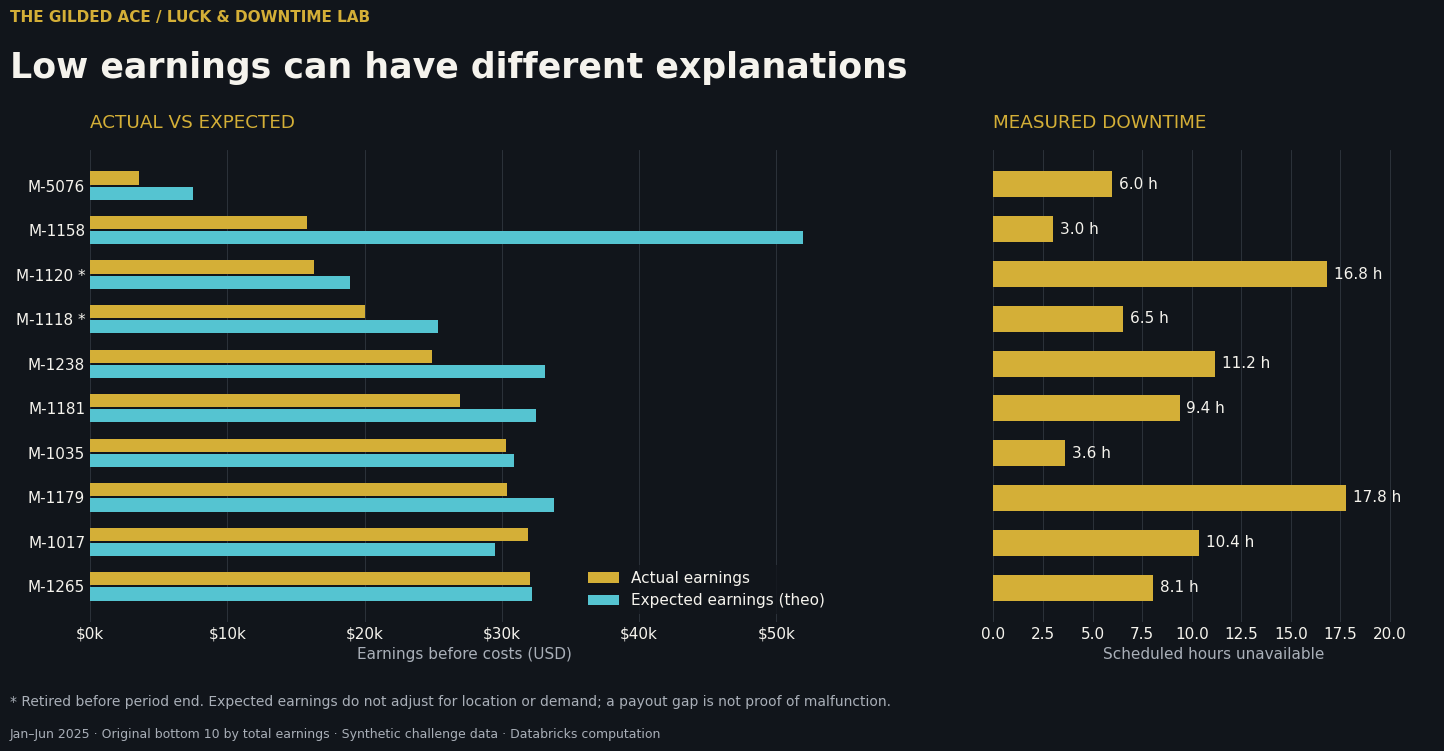

In [0]:
BG, FG, GOLD, MUTED, CYAN = '#11151B', '#F5F3ED', '#D4AF37', '#A9AFB8', '#55C4D1'
plt.rcParams.update({'font.size': 11, 'font.family':'DejaVu Sans'})
fig, axes = plt.subplots(1,2,figsize=(16,8), gridspec_kw={'width_ratios':[1.7,1]}, facecolor=BG)
fig.subplots_adjust(left=.11, right=.95, top=.77, bottom=.18, wspace=.26)
y=np.arange(len(bottom))
labels=[f"{r.machine_id}{' *' if not r.on_floor_at_period_end else ''}" for r in bottom.itertuples()]
axes[0].barh(y-.17, bottom.actual_usd, height=.30, color=GOLD, label='Actual earnings')
axes[0].barh(y+.17, bottom.expected_usd, height=.30, color=CYAN, label='Expected earnings (theo)')
axes[0].set_yticks(y,labels)
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x,_:f'${x/1000:,.0f}k'))
axes[0].set_xlabel('Earnings before costs (USD)',color=MUTED)
axes[0].legend(facecolor=BG, edgecolor='none', labelcolor=FG, loc='lower right')
axes[0].set_title('ACTUAL VS EXPECTED',color=GOLD,loc='left',pad=16)
axes[1].barh(y,bottom.downtime_hours,height=.58,color=GOLD)
axes[1].set_yticks(y,['']*10)
axes[1].set_xlim(0,max(bottom.downtime_hours)*1.25)
for i,v in enumerate(bottom.downtime_hours):
    axes[1].text(v+.35,i,f'{v:.1f} h',color=FG,va='center')
axes[1].set_xlabel('Scheduled hours unavailable',color=MUTED)
axes[1].set_title('MEASURED DOWNTIME',color=GOLD,loc='left',pad=16)
for ax in axes:
    ax.set_facecolor(BG); ax.invert_yaxis(); ax.set_axisbelow(True)
    ax.grid(axis='x',color='#313740',linewidth=.6)
    ax.tick_params(colors=FG,length=0)
    for spine in ax.spines.values(): spine.set_visible(False)
fig.text(.06,.93,'THE GILDED ACE / LUCK & DOWNTIME LAB',color=GOLD,weight='bold',fontsize=11)
fig.text(.06,.86,'Low earnings can have different explanations',color=FG,weight='bold',fontsize=25)
fig.text(.06,.075,'* Retired before period end. Expected earnings do not adjust for location or demand; a payout gap is not proof of malfunction.',color=MUTED,fontsize=10)
fig.text(.06,.035,'Jan–Jun 2025 · Original bottom 10 by total earnings · Synthetic challenge data · Databricks computation',color=MUTED,fontsize=9)
fig.savefig(EXPORT/'luck_vs_downtime.png',dpi=200,facecolor=BG)
display(fig)
plt.close(fig)


## 3. Interactive “repair first?” scenario
**Historical counterfactual, not a July forecast:** downtime hours × observed theo per available hour × recovery fraction × retained additional play fraction.

This assumes unavailable hours would have had the same play intensity as available hours. It may overstate or understate missed demand. Guests may have switched machines; the retention control reduces that assumed floor-wide benefit. Zero is a valid scenario. Costs have not been deducted, so this is not profit or ROI.


In [0]:
row = bottom[bottom.machine_id==selected].iloc[0]
scenario = row.historical_downtime_theo_proxy_usd * recovery * retention
cards = [
    ('Actual earnings',f'${row.actual_usd:,.2f}'),
    ('Expected earnings',f'${row.expected_usd:,.2f}'),
    ('Actual minus expected',f'${row.payout_deviation_usd:,.2f}'),
    ('Downtime / availability',f'{row.downtime_hours:.2f} h / {row.availability:.2%}'),
    ('Historical recovery scenario',f'${scenario:,.2f} before costs'),
]
card_html=''.join(f'<div style="flex:1;min-width:170px;padding:18px;background:#1d232c;border-top:3px solid {GOLD}"><div style="font-size:12px;color:{MUTED}">{html.escape(k)}</div><div style="font-size:22px;margin-top:10px">{html.escape(v)}</div></div>' for k,v in cards)
state='On floor at June 30' if row.on_floor_at_period_end else 'Retired — exclude from July replacement candidates'
displayHTML(f'<div style="background:{BG};color:{FG};padding:26px;font-family:Arial"><h2 style="color:{GOLD}">{selected}: investigate before replacing</h2><p>{state}. Active {int(row.active_days)} days.</p><div style="display:flex;gap:12px;flex-wrap:wrap">{card_html}</div><p style="color:{MUTED}">Scenario: recover {recovery:.0%} of downtime; retain {retention:.0%} as additional floor play. This is an assumption-driven historical estimate.</p></div>')

display(bottom[['machine_id','active_days','on_floor_at_period_end','actual_usd','expected_usd',
                'payout_deviation_usd','downtime_hours','availability','expected_per_available_hour',
                'historical_downtime_theo_proxy_usd','standardized_payout_deviation']])


M-1158: investigate before replacing On floor at June 30. Active 181 days. Actual earnings $15,796.25 Expected earnings $51,961.00 Actual minus expected $-36,164.75 Downtime / availability 3.01 h / 99.93% Historical recovery scenario $9.02 before costs Scenario: recover 50% of downtime; retain 50% as additional floor play. This is an assumption-driven historical estimate.

machine_id,active_days,on_floor_at_period_end,actual_usd,expected_usd,payout_deviation_usd,downtime_hours,availability,expected_per_available_hour,historical_downtime_theo_proxy_usd,standardized_payout_deviation
M-5076,49,true,3573.25,7478.7,-3905.45,6.0,0.99489795918,6.392051,38.352308,-1.8533196975080724
M-1158,181,true,15796.25,51961.0,-36164.75,3.014722,0.99930584343,11.972621,36.094125,-4.570145654700794
M-1120,132,false,16355.0,18910.925,-2555.925,16.836389,0.99468380518,6.003156,101.071477,-0.7880275251239047
M-1118,55,false,20050.0,25329.0,-5279.0,6.536389,0.99504819015,19.284128,126.04856,-0.6487889821746958
M-1238,181,true,24932.75,33139.3125,-8206.5625,11.196389,0.99742196892,7.650234,85.654999,-1.8154284056368424
M-1181,181,true,26977.0,32516.16,-5539.16,9.382222,0.997839691,7.503237,70.397033,-2.405913894260882
M-1035,181,true,30303.5,30894.6,-591.1,3.613611,0.99916794589,7.119578,25.727385,-0.13615500848095216
M-1179,181,true,30393.75,33784.7,-3390.95,17.773333,0.99590759084,7.811082,138.828961,-1.4550026667788536
M-1017,181,true,31939.5,29525.6375,2413.8625,10.389167,0.99760783629,6.814745,70.799523,0.578161535638087
M-1265,181,true,32071.0,32208.88,-137.88,8.053611,0.9981456111,7.430053,59.838754,-0.06015234666361228


## 4. Test the alternative explanation
A large payout gap can reflect random variation, configuration problems or meter/reporting issues. For context we calculate a standardized deviation using the supplied per-spin payout variance and sum of squared bets:

`standard deviation = sqrt(sum(payout variance × squared bets)) / 100`

This assumes independent spins and correct game settings. The result is a screening signal, **not a calibrated probability or proof of wrongdoing**. We selected these machines for low earnings, so negative deviations are expected in this group. We should inspect time patterns and comparable machines before recommending replacement or inspection.


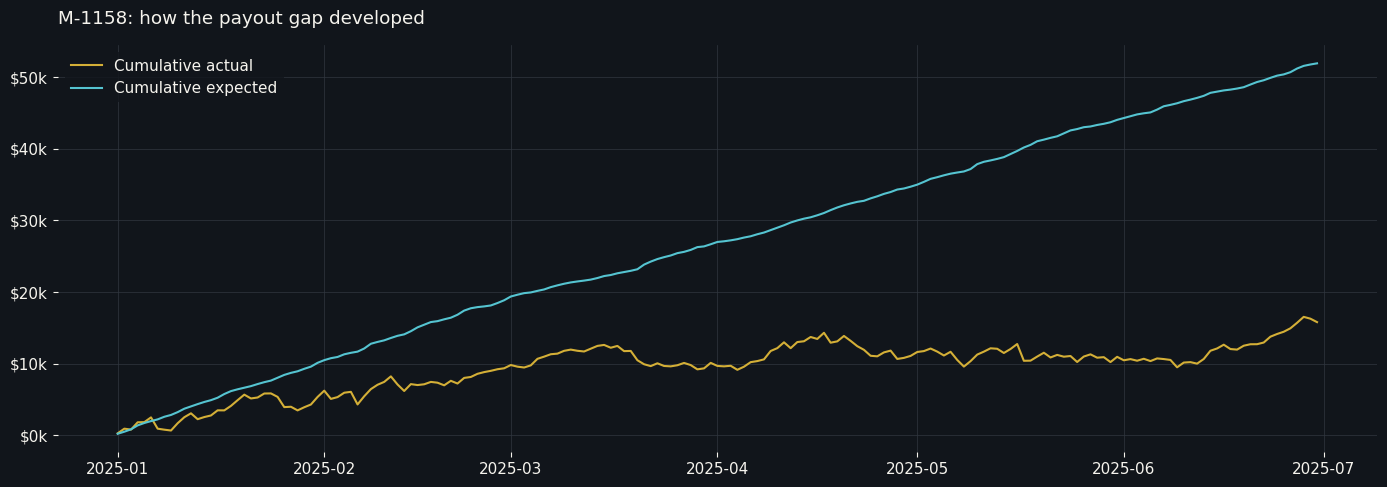

operation_id,machine_id,location_id,event_type,opened_at_utc,opened_at_local,recorded_at_utc,work_started_at_utc,available_at_utc,direct_cost_cents
OP7983419320fb68d6,M-1158,L-31-4,fault_repair,2025-03-10T08:17:53.000,2025-03-10T01:17:53.000,2025-03-10T08:26:59.000,2025-03-10T10:17:04.000,2025-03-10T11:18:46.000,8436


In [0]:
timeline = (daily.filter((F.col('machine_id')==selected)&F.col('active'))
            .select('gaming_date','house_win_usd','theo_usd').orderBy('gaming_date').toPandas())
timeline['gaming_date']=pd.to_datetime(timeline['gaming_date'])
for c in ['house_win_usd','theo_usd']: timeline[c]=pd.to_numeric(timeline[c])
fig,ax=plt.subplots(figsize=(14,5),facecolor=BG)
ax.set_facecolor(BG)
ax.plot(timeline.gaming_date,timeline.house_win_usd.cumsum(),color=GOLD,label='Cumulative actual')
ax.plot(timeline.gaming_date,timeline.theo_usd.cumsum(),color=CYAN,label='Cumulative expected')
ax.set_title(f'{selected}: how the payout gap developed',color=FG,loc='left',pad=15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x,_:f'${x/1000:,.0f}k'))
ax.tick_params(colors=FG); ax.grid(color='#313740',linewidth=.5)
ax.legend(facecolor=BG,labelcolor=FG,edgecolor='none')
for spine in ax.spines.values(): spine.set_visible(False)
fig.tight_layout()
fig.savefig(EXPORT/f'{selected}_cumulative_earnings.png',dpi=200,facecolor=BG)
display(fig); plt.close(fig)
display(operations.filter(F.col('machine_id')==selected).orderBy('opened_at_utc'))


## 5. A creative solution: triage before replacement
Use an evidence-driven decision board:
- **Payout review:** actual earnings far below expectation with little downtime → inspect settings and payout history before replacing.
- **Repair opportunity:** substantial downtime and healthy expected earnings per available hour → evaluate maintenance and recoverable demand.
- **Demand/location review:** low expected earnings per available hour despite good availability → compare similar games and locations.
- **Lifecycle check:** retired machines cannot be replaced again; new machines require fair exposure comparisons.

These are investigation routes, not automatic spending recommendations. Costs and effects must be validated against the action catalogue before allocating the $100,000.

**Useful contrast:** the original bottom ten may not contain the largest repair opportunities. The next table searches the whole floor for downtime among machines still present at period end.


In [0]:
display(pdf[pdf.on_floor_at_period_end].sort_values('downtime_hours',ascending=False).head(10)[
    ['machine_id','actual_usd','expected_usd','downtime_hours','availability','historical_downtime_theo_proxy_usd']])
summary = {'rows_checked':daily.count(),'machines':len(pdf),'selected_machine':selected,
           'recovery_assumption':recovery,'retained_play_assumption':retention,
           'selected_historical_recovered_theo_usd':float(scenario),
           'bottom10':json.loads(bottom.to_json(orient='records',date_format='iso')),
           'largest_downtime':json.loads(pdf[pdf.on_floor_at_period_end].sort_values('downtime_hours',ascending=False).head(10).to_json(orient='records',date_format='iso'))}
(EXPORT/'luck_downtime_results.json').write_text(json.dumps(summary,indent=2))
print(f'Analysis complete. Results saved to {EXPORT}.')


machine_id,actual_usd,expected_usd,downtime_hours,availability,historical_downtime_theo_proxy_usd
M-1065,47923.25,52171.06,81.114722,0.98132288234,992.950479
M-1002,87978.4,91941.652,72.351111,0.98334075271,1557.627621
M-1176,94568.75,82815.95,65.686667,0.98487527815,1271.803889
M-1095,39587.0,44183.375,64.723889,0.98509696316,668.428074
M-1078,83090.6,83490.22,62.5775,0.98559118121,1220.582604
M-1112,102093.6,98601.12,60.426111,0.98608655054,1391.238628
M-1241,63421.25,67982.05,57.363056,0.98679183606,909.936654
M-1028,82645.2,92143.128,55.678333,0.98717975294,1196.638872
M-1036,97028.0,93922.64,54.686111,0.98740821759,1197.735065
M-1015,64453.75,63829.86,50.773889,0.98830902855,755.060461


Analysis complete. Results saved to /Volumes/workspace/default/dashboard_royale_source/analysis_exports.


# 6. Complete analysis: demand, players, comps and the decision lab

This reusable function validates source tables, estimates historical downtime opportunity, summarizes guests and loyalty, evaluates a time-split demand forecast, and searches a disclosed action shortlist using 1,000 shared scenarios. Source hashes and assumptions are exported for reproducibility.

**Important limits:** event/location comparisons are associations; missed machine play need not be lost floor play; comp and intervention effects are assumptions. Information value is unpriced. The search is exhaustive only within this shortlist, not every possible catalogue quantity and target.

Saved results below come from the successful [full Databricks run](https://dbc-3501c3c5-1cc4.cloud.databricks.com/?o=7474651870217400#job/1101185085183547/run/614558976320488). They are embedded so judges can read them without rerunning.


In [0]:
"""Reproducible retrospective analysis and assumption-driven July decision search.

Run locally: python analysis/pipeline.py --data PATH_TO_DATA --output data
The same run() function is executed in Databricks against the project volume.
"""
from pathlib import Path
from itertools import combinations
import argparse
import hashlib
import io
import json
import math
import numpy as np
import pandas as pd


def records(df):
    return json.loads(df.to_json(orient='records', date_format='iso'))


def run(root, output, execution='local'):
    root, output = Path(root), Path(output)
    output.mkdir(parents=True, exist_ok=True)
    sources = {}
    def read(name):
        direct = root/(name+'.parquet')
        files = [direct] if direct.is_file() else list(root.rglob(name+'.parquet'))
        assert len(files) == 1, (name, files)
        p = files[0]
        sources[name] = {'sha256':hashlib.sha256(p.read_bytes()).hexdigest(), 'file':p.name}
        df = pd.read_parquet(p)
        for c in df.columns:
            if (c.endswith(('_usd','_cents')) and not df[c].astype(str).str.contains('|',regex=False).any()) or c in ['configured_rtp','payout_multiplier_variance']:
                df[c] = pd.to_numeric(df[c])
        return df

    d=read('prepared_daily_view'); prop=read('property_day'); players=read('player_period')
    meters=read('machine_day'); machines=read('machines'); gm=read('game_math')
    actions=read('action_catalog'); ledger=read('loyalty_ledger')
    traffic=read('zone_traffic_hourly'); events=read('events')
    for df in [d,prop,meters]: df['gaming_date']=pd.to_datetime(df.gaming_date)
    for col in ['install_date','retire_date']: machines[col]=pd.to_datetime(machines[col])
    assert not d.duplicated(['machine_id','gaming_date']).any()
    assert not meters.duplicated(['machine_id','gaming_date']).any()
    assert not prop.gaming_date.duplicated().any()
    a=d[d.active].copy()
    assert np.allclose(a.coin_in_usd-a.payout_usd,a.house_win_usd,atol=.001)
    assert np.allclose(a.coin_in_usd*(1-a.configured_rtp),a.theo_usd,atol=.0001)
    assert abs(a.house_win_usd.sum()-prop.house_win_usd.sum()) < .01
    assert np.allclose(players.tracked_payout_usd-players.tracked_coin_in_usd,players.tracked_net_usd,atol=.001)
    a=a.merge(meters[['machine_id','gaming_date','scheduled_seconds','available_seconds','sum_bet_squared']],on=['machine_id','gaming_date'],validate='one_to_one')
    a=a.merge(gm[['config_id','payout_multiplier_variance']],on='config_id',validate='many_to_one')
    assert a.available_seconds.between(0,a.scheduled_seconds).all()
    a['scheduled_hours']=a.scheduled_seconds/3600
    a['down_hours']=(a.scheduled_seconds-a.available_seconds)/3600
    a['weekday']=a.gaming_date.dt.dayofweek
    a['variance_usd2']=a.sum_bet_squared*a.payout_multiplier_variance/10000
    a['coin_per_hour']=a.coin_in_usd/a.available_hours.replace(0,np.nan)
    # Retrospective rate estimates: only days with at least 20 available hours.
    operating=a[a.available_hours>=20]
    rates=operating.groupby(['machine_id','weekday']).coin_per_hour.quantile([.25,.5,.75]).unstack()
    fallback=operating.groupby('machine_id').coin_per_hour.quantile([.25,.5,.75]).unstack()
    a=a.join(rates.rename(columns={.25:'rate_low',.5:'rate_mid',.75:'rate_high'}),on=['machine_id','weekday'])
    for q,col in [(.25,'rate_low'),(.5,'rate_mid'),(.75,'rate_high')]:
        a[col]=a[col].fillna(a.machine_id.map(fallback[q]))
        a[col]=a[col].fillna(operating.coin_per_hour.median())
        a['missed_wagers_'+col.split('_')[1]]=a.down_hours*a[col]
    a['missed_theo_mid']=a.missed_wagers_mid*(1-a.configured_rtp)
    agg={'house_win_usd':'sum','theo_usd':'sum','coin_in_usd':'sum','available_hours':'sum',
         'scheduled_hours':'sum','down_hours':'sum','variance_usd2':'sum','missed_theo_mid':'sum',
         'missed_wagers_low':'sum','missed_wagers_mid':'sum','missed_wagers_high':'sum'}
    m=a.groupby('machine_id').agg(agg).reset_index()
    m=m.merge(a.groupby('machine_id').gaming_date.agg(active_days='count',first_day='min',last_day='max'),on='machine_id')
    m=m.merge(machines,on='machine_id',validate='one_to_one')
    m['eligible_july']=(m.install_date<=pd.Timestamp('2025-07-01')) & (m.retire_date.isna() | (m.retire_date>pd.Timestamp('2025-07-01')))
    m['availability']=m.available_hours/m.scheduled_hours
    m['theo_per_hour']=m.theo_usd/m.available_hours.replace(0,np.nan)
    m['actual_per_day']=m.house_win_usd/m.active_days
    m['payout_gap']=m.house_win_usd-m.theo_usd
    m['payout_sd']=np.sqrt(m.variance_usd2)
    m['standardized_gap']=m.payout_gap/m.payout_sd.replace(0,np.nan)
    m=m.sort_values(['house_win_usd','machine_id'])
    # Same game/theme is a descriptive peer comparison, not location-adjusted causality.
    m['theme_peer_theo_per_hour']=m.groupby('theme').theo_per_hour.transform('median')
    m['peer_ratio']=m.theo_per_hour/m.theme_peer_theo_per_hour

    prop=prop.sort_values('gaming_date'); prop['month']=prop.gaming_date.dt.strftime('%Y-%m')
    prop['weekday']=prop.gaming_date.dt.dayofweek
    monthly=prop.groupby('month').agg(days=('gaming_date','count'),wagers=('coin_in_usd','sum'),actual=('house_win_usd','sum'),expected=('theo_usd','sum'),comps=('comp_cost_usd','sum'),comp_face=('comp_face_value_usd','sum'),hours=('available_machine_hours','sum')).reset_index()
    monthly['wagers_per_day']=monthly.wagers/monthly.days
    monthly['wagers_per_available_hour']=monthly.wagers/monthly.hours
    monthly['comp_cost_per_theo']=monthly.comps/monthly.expected
    zone=a.groupby(['month','zone_name','bank_id']).agg(wagers=('coin_in_usd','sum'),theo=('theo_usd','sum'),available_hours=('available_hours','sum'),downtime_hours=('down_hours','sum')).reset_index()
    zone['wagers_per_available_hour']=zone.wagers/zone.available_hours
    ev=[]
    # Weekday-adjusted associations use non-event days as the baseline. Not causal effects.
    non_event=prop[prop.events_active.isna() | prop.events_active.eq('')]
    week_baseline=non_event.groupby('weekday').coin_in_usd.mean()
    for row in events.itertuples():
        sub=prop[prop.gaming_date.between(pd.Timestamp(row.start_date),pd.Timestamp(row.end_date))]
        expected=sub.weekday.map(week_baseline).fillna(non_event.coin_in_usd.mean()).sum()
        ev.append({'event':row.name,'start':str(row.start_date),'end':str(row.end_date),'days':len(sub),
                   'wagers':float(sub.coin_in_usd.sum()),'weekday_baseline':float(expected),
                   'difference_pct':float(sub.coin_in_usd.sum()/expected-1) if expected else None})
    # Hourly sensors count entries, not people. Exclude offline/missing intervals.
    traffic['gaming_date']=(pd.to_datetime(traffic.hour_start_local)-pd.Timedelta(hours=6)).dt.normalize()
    traffic['month']=traffic.gaming_date.dt.strftime('%Y-%m')
    traffic['valid']=traffic.entries_count.notna() & (traffic.coverage_minutes>0)
    traffic['entries_count']=traffic.entries_count.where(traffic.valid)
    traffic['coverage_minutes']=traffic.coverage_minutes.where(traffic.valid,0)
    sensor=traffic.groupby(['month','zone_id']).agg(observed_entries=('entries_count',lambda x:x.sum(min_count=1)),covered_minutes=('coverage_minutes','sum'),valid_intervals=('valid','sum'),intervals=('valid','size')).reset_index()
    sensor['entries_per_covered_hour']=sensor.observed_entries/(sensor.covered_minutes/60)
    sensor['valid_interval_share']=sensor.valid_intervals/sensor.intervals

    # Player totals and concentration: sum each player over the whole six months first.
    p=players.groupby('player_id')[['tracked_coin_in_usd','tracked_payout_usd','tracked_net_usd']].sum()
    n_top=max(1,math.ceil(len(p)*.01)); losses=(-p.tracked_net_usd).clip(lower=0)
    player_summary={'tracked_players':len(p),'tracked_wagers':float(p.tracked_coin_in_usd.sum()),
                    'tracked_payouts':float(p.tracked_payout_usd.sum()),'player_net':float(p.tracked_net_usd.sum()),
                    'players_ahead_share':float((p.tracked_net_usd>0).mean()),
                    'top1pct_count':n_top,'top1pct_wager_share':float(p.tracked_coin_in_usd.nlargest(n_top).sum()/p.tracked_coin_in_usd.sum()),
                    'top1pct_positive_loss_share':float(losses.nlargest(n_top).sum()/losses.sum()),
                    'tracked_wager_coverage':float(p.tracked_coin_in_usd.sum()/prop.coin_in_usd.sum())}
    guests=players.groupby(['period_month','home_region','age_band'],dropna=False).agg(
        wagers=('tracked_coin_in_usd','sum'),payouts=('tracked_payout_usd','sum'),player_net=('tracked_net_usd','sum'),
        expected=('theo_usd','sum'),comp_cost=('comp_cost_usd','sum'),player_months=('player_id','count')).reset_index()
    # Correct local gaming day for ledger timestamps, including daylight saving.
    local_time=pd.to_datetime(ledger.event_at_utc,utc=True).dt.tz_convert('America/Los_Angeles').dt.tz_localize(None)
    ledger['gaming_month']=(local_time-pd.Timedelta(hours=6)).dt.strftime('%Y-%m')
    redeemed=ledger[(ledger.event_type=='redeem') & ledger.gaming_month.between('2025-01','2025-06')].copy()
    loyalty=redeemed.groupby('gaming_month').agg(points_delta=('points_delta','sum'),face_cents=('face_value_cents','sum'),cost_cents=('economic_cost_cents','sum'),redemptions=('loyalty_event_id','count')).reset_index()
    loyalty['points_per_face_dollar']=-loyalty.points_delta/(loyalty.face_cents/100)
    assert abs(loyalty.cost_cents.sum()/100-prop.comp_cost_usd.sum()) < .01

    # Freeze both forecasts on Jan-Apr and evaluate May-Jun without future inputs.
    train=prop[prop.gaming_date<'2025-05-01'].copy(); test=prop[prop.gaming_date>='2025-05-01'].copy()
    weekday_means=train.groupby('weekday').coin_in_usd.mean(); baseline=train.coin_in_usd.mean()
    test['weekday_prediction']=test.weekday.map(weekday_means); test['constant_prediction']=baseline
    weekday_mae=float((test.coin_in_usd-test.weekday_prediction).abs().mean())
    constant_mae=float((test.coin_in_usd-test.constant_prediction).abs().mean())
    winner='weekday' if weekday_mae<constant_mae else 'constant'
    forecast={'train_start':'2025-01-01','train_end':'2025-04-30','test_start':'2025-05-01','test_end':'2025-06-30',
              'weekday_mae':weekday_mae,'constant_mae':constant_mae,'winner':winner,
              'improvement_pct':1-min(weekday_mae,constant_mae)/constant_mae,
              'test_rows':records(test[['gaming_date','coin_in_usd','weekday_prediction','constant_prediction']])}
    july=pd.date_range('2025-07-01','2025-07-30')
    july_pred=prop.groupby('weekday').coin_in_usd.mean().reindex(july.dayofweek).to_numpy() if winner=='weekday' else np.repeat(prop.coin_in_usd.mean(),30)
    forecast['july_refit_baseline_wagers']=float(july_pred.sum())
    forecast['july_refit_note']='Winner refit on Jan-Jun after holdout evaluation; July is a scenario, not a validated forecast.'

    # Candidate set is deliberately small. Effects below are ASSUMPTIONS, not treatment estimates.
    rng=np.random.default_rng(20251107); N=1000
    fitted=train.weekday.map(weekday_means) if winner=='weekday' else pd.Series(baseline,index=train.index)
    errors=(train.coin_in_usd/fitted).to_numpy()
    demand=rng.choice(errors,size=(N,30),replace=True).mean(axis=1)
    retention=rng.triangular(.25,.5,1,size=N)
    catalog=actions.set_index('action_type_id')
    candidates=[]; samples=[]; conservative=[]
    eligible=m[m.eligible_july & (m.active_days>=28)]
    weak=eligible.sort_values('theo_per_hour').iloc[0]
    busiest_down=eligible.sort_values('missed_theo_mid',ascending=False).iloc[0]
    manuf=eligible.groupby('manufacturer').missed_theo_mid.sum().idxmax()
    zone_tot=a.groupby('zone_name').agg(theo=('theo_usd','sum'),hours=('available_hours','sum'))
    zone_name=(zone_tot.theo/zone_tot.hours).idxmin()
    def add(key,aid,target,benefit,assumption,targets=(),extra_downtime_cost=0,conservative_benefit=0):
        rule=catalog.loc[aid]; days=max(0,30-int(rule.lead_days))
        cost=float(rule.unit_cost_cents+rule.recurring_cost_cents_per_day*days)/100
        assert int(rule.quantity_limit)>=1
        b=np.broadcast_to(benefit,(N,)).astype(float)
        samples.append(b-cost-extra_downtime_cost)
        conservative.append(float(conservative_benefit)-cost-extra_downtime_cost)
        candidates.append({'id':key,'action_type':aid,'name':rule['name'],'target':str(target),'quantity':1,
                           'cost':cost,'lead_days':int(rule.lead_days),'benefit_days':days,
                           'catalogue_downtime_minutes':int(rule.downtime_minutes),'additional_theo_cost':float(extra_downtime_cost),
                           'targets':list(targets),'assumption':assumption,
                           'expected_net':float(samples[-1].mean())})
    # Inspection buys information. No unpriced correction benefit is silently credited.
    for mid in ['M-1158','M-1181']:
        r=eligible[eligible.machine_id==mid].iloc[0]
        add('inspect_'+mid,'A-INSPECT',mid,0,'Information only; no cash recovery credited without a corrective-action estimate.',[mid],2*r.theo_per_hour)
    base=float(weak.theo_usd/weak.active_days)
    move_effect=rng.triangular(-.1,.2,.6,size=N)
    add('move_weak','A-MOVE-MACHINE',weak.machine_id,base*28*move_effect*retention*demand,
        'Incremental play uplift triangular(-10%,20%,60%); floor retention triangular(25%,50%,100%). Destination not yet chosen; exploratory candidate.',[weak.machine_id],3*weak.theo_per_hour,
        conservative_benefit=base*28*(-.1))
    lease_uplift=rng.triangular(-.1,.5,1.5,size=N)
    add('lease_weak','A-REPLACE-LEASE',weak.machine_id,base*16*lease_uplift*retention*demand,
        'New title uplift triangular(-10%,50%,150%); floor retention 25%-100%; no observed replacement effect claimed.',[weak.machine_id],6*weak.theo_per_hour,conservative_benefit=-.1*base*16)
    floor_downtime=float(eligible.missed_theo_mid.sum())/181*23
    add('technician','A-TECH-SHIFT','One additional shift; roster to select',floor_downtime*rng.triangular(.1,.3,.6,N)*retention*demand,
        'Recovers 10%-60% (mode30%) of historical downtime opportunity scaled to 23 July days; assumes one shift can cover this opportunity.',eligible.machine_id.tolist())
    mf=eligible[eligible.manufacturer==manuf]
    add('preventive','A-PREVENTIVE',manuf,float(mf.missed_theo_mid.sum())/181*23*rng.triangular(.2,.5,.8,N)*retention*demand,
        'Recovers 20%-80% (mode50%) of manufacturer downtime; planned 90 minutes per machine deducted.',mf.machine_id.tolist(),1.5*mf.theo_per_hour.sum())
    zonebase=float(zone_tot.loc[zone_name,'theo'])/181*20
    add('signage','A-WAYFINDING',zone_name,zonebase*rng.triangular(0,.025,.08,N)*retention*demand,
        'Zone play uplift triangular(0%,2.5%,8%); retained incremental floor play 25%-100%. Observational location differences are not causal effects.',a[a.zone_name==zone_name].machine_id.unique().tolist())
    compbase=float(prop.comp_cost_usd.sum())/181*27
    theobase=float(prop.theo_usd.sum())/181*27
    comp_savings=rng.triangular(0,.1,.25,N); demand_loss=rng.triangular(0,.0005,.002,N)
    add('comp_policy','A-COMP-CHANGE','Floor-wide: proposed 12 points per comp face-value dollar',
        compbase*comp_savings-theobase*demand_loss*demand,
        'Proposed rate12 (catalogue range5-20); savings0%-25% (mode10%) and loss of expected gaming earnings0%-0.2% (mode0.05%) are assumptions, not proven effects.',
        conservative_benefit=-theobase*.002)
    add('comp_pilot','A-COMP-PILOT','Randomized pilot with unchanged total comp budget',0,
        'Information-only test; no immediate benefit or additional comp spend credited. Cannot combine with floor-wide change.')
    # Portfolios: <=3 action types, within budget, one unit of each explicit candidate.
    # Reject overlapping targets to avoid double-counting recovery or demand benefits.
    portfolios=[]; arr=np.vstack(samples)
    for k in range(len(candidates)+1):
        for combo in combinations(range(len(candidates)),k):
            cs=[candidates[i] for i in combo]
            if len(set(c['action_type'] for c in cs))>3 or sum(c['cost'] for c in cs)>100000: continue
            ids={c['id'] for c in cs}
            if {'comp_policy','comp_pilot'}<=ids: continue
            if any(set(candidates[i]['targets']) & set(candidates[j]['targets']) for i,j in combinations(combo,2)): continue
            # Floor-wide comp demand effects can overlap other play interventions: isolate them.
            if 'comp_policy' in ids and any(c['action_type'] not in ['A-COMP-CHANGE','A-INSPECT'] for c in cs): continue
            net=arr[list(combo)].sum(axis=0) if combo else np.zeros(N)
            portfolios.append({'actions':[c['id'] for c in cs],'cost':sum(c['cost'] for c in cs),
                'mean_net':float(net.mean()),'median_net':float(np.median(net)),
                'p10':float(np.quantile(net,.1)),'p90':float(np.quantile(net,.9)),
                'probability_positive':float((net>0).mean()),'conservative_net':sum(conservative[i] for i in combo)})
    portfolios.sort(key=lambda p:(-p['mean_net'],p['cost']))
    simulation={'seed':20251107,'scenarios':N,'objective':'Maximize expected 30-day incremental contribution',
                'horizon':'2025-07-01 to 2025-07-30','candidate_count':len(candidates),
                'feasible_portfolios':len(portfolios),'candidates':candidates,'portfolios':portfolios,
                'recommended':portfolios[0], 'learning_option':['inspect_M-1158'],
                'limitations':['Effects are assumed, not causal estimates. Probabilities are conditional on assumptions.',
                              'Simulation concerns theoretical contribution, not realized payout profit.',
                              'Common demand scenarios are used for all portfolios; shocks are bootstrapped independently by day.',
                              'Search is exhaustive only within this limited candidate list and conservative overlap exclusions.',
                              'Information value is unpriced; information-only actions may be worthwhile beyond 30 days.',
                              'Moving/replacement/signage targets require location and operational feasibility checks before implementation.']}

    # Unity Catalog volumes require sequential writes, not ZIP's random seeks.
    scenario_buffer=io.BytesIO()
    np.savez_compressed(scenario_buffer,net=arr)
    (output/'scenario_net.npz').write_bytes(scenario_buffer.getvalue())

    daily_out=a[['machine_id','gaming_date','month','zone_name','bank_id','config_id','house_win_usd','theo_usd','coin_in_usd','available_hours','scheduled_hours','down_hours','missed_wagers_low','missed_wagers_mid','missed_wagers_high','missed_theo_mid']].copy()
    daily_out.to_parquet(output/'machine_daily.parquet',index=False)
    prop.to_parquet(output/'property_daily.parquet',index=False)
    guests.to_parquet(output/'guest_groups.parquet',index=False)
    m.to_parquet(output/'machines.parquet',index=False)
    report={'execution':execution,'sources':sources,'validation':{'rows':len(d),'active_rows':len(a),'dates':[str(prop.gaming_date.min().date()),str(prop.gaming_date.max().date())],'money_and_ledger_reconciled':True},
            'monthly':records(monthly),'zone_monthly':records(zone),'event_associations':ev,'traffic':records(sensor),
            'players':player_summary,'loyalty':records(loyalty),'forecast':forecast,'simulation':simulation,
            'downtime':{'hours':float(a.down_hours.sum()),'missed_wagers_low':float(a.missed_wagers_low.sum()),
                        'missed_wagers_mid':float(a.missed_wagers_mid.sum()),'missed_wagers_high':float(a.missed_wagers_high.sum()),
                        'missed_theo_mid':float(a.missed_theo_mid.sum()),
                        'method':'Machine-by-weekday operating-day hourly wager rate, 25th/50th/75th percentiles; machine/global fallback. Historical machine opportunity, not net floor loss or confidence interval.'},
            'bottom10':records(m.head(10)), 'action_catalog':records(actions)}
    (output/'analysis_results.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
    return report




In [0]:
report = run('/Volumes/workspace/default/dashboard_royale_source', '/Volumes/workspace/default/dashboard_royale_source/app_exports', execution='Databricks')
print('Validated and exported:', report['validation'])


{
  "rows": 56110,
  "active_rows": 55092,
  "dates": [
    "2025-01-01",
    "2025-06-30"
  ],
  "money_and_ledger_reconciled": true
}


## Demand and downtime
Use per-day and per-available-hour demand to avoid month-length and exposure bias. Historical downtime opportunity is a sensitivity estimate, not proven lost floor revenue.

In [0]:
display(pd.DataFrame(report['monthly']))
display(pd.DataFrame(report['event_associations']))
print(json.dumps(report['downtime'],indent=2))

month,days,wagers,actual,expected,comps,comp_face,hours,wagers_per_day,wagers_per_available_hour,comp_cost_per_theo
2025-01,31,41676918.15,3936193.75,3946193.9760,28750.3,103499.5,222333.459444,1.344417e+06,187.452299,0.007286
2025-02,28,39577371.95,3889478.30,3755949.8405,29854.3,106853.5,200827.509167,1.413478e+06,197.071468,0.007949
2025-03,31,43647425.45,4108214.25,4132019.4420,33255.5,119167.5,223456.803889,1.407981e+06,195.328246,0.008048
2025-04,30,41288570.55,3864536.65,3899006.3145,31390.3,112214.0,221004.932222,1.376286e+06,186.821942,0.008051
2025-05,31,42984383.30,4023535.85,4060078.6170,34446.1,123048.5,228134.689167,1.386593e+06,188.416691,0.008484
2025-06,30,39730549.85,3816196.30,3752116.2885,32972.8,117966.5,221129.527222,1.324352e+06,179.670939,0.008788


event,start,end,days,wagers,weekday_baseline,difference_pct
CES,2025-01-07,2025-01-10,4,5166884.40,5.094944e+06,0.014120
Super Bowl LIX weekend,2025-02-07,2025-02-09,3,5831329.05,4.742419e+06,0.229611
College basketball tournament opening rounds,2025-03-20,2025-03-23,4,7163708.05,6.013421e+06,0.191287
CinemaCon,2025-03-31,2025-04-03,4,4817531.00,4.689024e+06,0.027406
NAB Show,2025-04-05,2025-04-09,5,6928996.00,6.559569e+06,0.056319
EDC Las Vegas festival weekend,2025-05-16,2025-05-18,3,5479462.75,4.742419e+06,0.155415
Gilded Ace Winter Slot Tournament,2025-02-21,2025-02-23,3,5583941.15,4.742419e+06,0.177446
Gilded Ace Locals Appreciation Week,2025-06-09,2025-06-15,7,9820264.10,9.431443e+06,0.041226


{
  "hours": 5021.078888888889,
  "missed_wagers_low": 856353.7586591465,
  "missed_wagers_mid": 990374.5526150785,
  "missed_wagers_high": 1138230.518955472,
  "missed_theo_mid": 92253.68459083037,
  "method": "Machine-by-weekday operating-day hourly wager rate, 25th/50th/75th percentiles; machine/global fallback. Historical machine opportunity, not net floor loss or confidence interval."
}


## Tracked guests
Player net means payouts less wagers. Concentration is calculated after aggregating every player across six months. Only tracked play is represented.

In [0]:
print(json.dumps(report['players'],indent=2))

{
  "tracked_players": 113890,
  "tracked_wagers": 163804869.64999998,
  "tracked_payouts": 148219409.05,
  "player_net": -15585460.600000001,
  "players_ahead_share": 0.13613135481605057,
  "top1pct_count": 1139,
  "top1pct_wager_share": 0.22859958424929527,
  "top1pct_positive_loss_share": 0.19860854533368733,
  "tracked_wager_coverage": 0.6581013855136345
}


## Comp economics
Reconciled redemption economic costs with the property totals. Points per face-value dollar is an observed weighted ratio; the sharp May change does not by itself prove a causal effect on demand.

In [0]:
display(pd.DataFrame(report['loyalty']))

gaming_month,points_delta,face_cents,cost_cents,redemptions,points_per_face_dollar
2025-01,-1433623,10349950,2875030,9171,13.851497
2025-02,-1411208,10685350,2985430,9292,13.206942
2025-03,-1531314,11916750,3325550,10430,12.850098
2025-04,-1404060,11221400,3139030,9702,12.512342
2025-05,-719172,12304850,3444610,10629,5.844622
2025-06,-673602,11796650,3297280,10137,5.710113


## Forecast validation
Train January–April; hold out May–June. Select the better constant or weekday model, then refit for the July planning baseline. July outcomes are not available.

In [0]:
print(json.dumps({k:v for k,v in report['forecast'].items() if k!='test_rows'},indent=2))
display(pd.DataFrame(report['forecast']['test_rows']))

{
  "train_start": "2025-01-01",
  "train_end": "2025-04-30",
  "test_start": "2025-05-01",
  "test_end": "2025-06-30",
  "weekday_mae": 68698.55169827497,
  "constant_mae": 218258.0969262295,
  "winner": "weekday",
  "improvement_pct": 0.6852416809925048,
  "july_refit_baseline_wagers": 40711161.62000001,
  "july_refit_note": "Winner refit on Jan-Jun after holdout evaluation; July is a scenario, not a validated forecast."
}


gaming_date,coin_in_usd,weekday_prediction,constant_prediction
2025-05-01T00:00:00.000,1291815.85,1.290980e+06,1.384919e+06
2025-05-02T00:00:00.000,1631269.55,1.655737e+06,1.384919e+06
2025-05-03T00:00:00.000,1743901.50,1.820595e+06,1.384919e+06
2025-05-04T00:00:00.000,1343811.50,1.465879e+06,1.384919e+06
2025-05-05T00:00:00.000,1070007.90,1.212138e+06,1.384919e+06
2025-05-06T00:00:00.000,991699.20,1.112942e+06,1.384919e+06
2025-05-07T00:00:00.000,1106454.35,1.149981e+06,1.384919e+06
2025-05-08T00:00:00.000,1203856.60,1.290980e+06,1.384919e+06
2025-05-09T00:00:00.000,1567783.00,1.655737e+06,1.384919e+06
2025-05-10T00:00:00.000,1755586.95,1.820595e+06,1.384919e+06


## The $100,000 decision
The selected objective is mean 30-day incremental contribution. All effects are explicit assumptions. Keep budget is a valid plan. Inspecting M-1158 buys information; no unsupported recovery benefit is credited.

In [0]:
display(pd.DataFrame(report['simulation']['candidates'])[['id','target','quantity','cost','lead_days','benefit_days','additional_theo_cost','expected_net','assumption']])
display(pd.DataFrame(report['simulation']['portfolios']).head(20))
print('Highest mean-benefit plan:',report['simulation']['recommended'])
print('Limitations:',*report['simulation']['limitations'],sep='\n- ')

id,action_type,name,target,quantity,cost,lead_days,benefit_days,catalogue_downtime_minutes,additional_theo_cost,assumption,expected_net
inspect_M-1158,A-INSPECT,Machine inspection and paytable verification,M-1158,1,1200.0,1,29,120,23.945243,Information only; no cash recovery credited without a corrective-action estimate.,-1223.945243
inspect_M-1181,A-INSPECT,Machine inspection and paytable verification,M-1181,1,1200.0,1,29,120,15.006473,Information only; no cash recovery credited without a corrective-action estimate.,-1215.006473
move_weak,A-MOVE-MACHINE,Relocate one machine,M-5076,1,1800.0,2,28,180,19.176154,"Incremental play uplift triangular(-10%,20%,60%); floor retention triangular(25%,50%,100%). Destination not yet chosen; exploratory candidate.",-1244.885205
lease_weak,A-REPLACE-LEASE,Replace a machine with a leased new title,M-5076,1,3380.0,14,16,360,38.352308,"New title uplift triangular(-10%,50%,150%); floor retention 25%-100%; no observed replacement effect claimed.",-2539.166547
technician,A-TECH-SHIFT,Add one technician to a shift for 30 days,One additional shift; roster to select,1,11520.0,7,23,0,0.000000,Recovers 10%-60% (mode30%) of historical downtime opportunity scaled to 23 July days; assumes one shift can cover this opportunity.,-9278.331140
preventive,A-PREVENTIVE,Preventive maintenance sweep for one manufacturer,Ridgeline,1,9000.0,7,23,90,2417.354624,Recovers 20%-80% (mode50%) of manufacturer downtime; planned 90 minutes per machine deducted.,-9606.856722
signage,A-WAYFINDING,Wayfinding and signage refresh for a zone,Back Forty,1,7500.0,10,20,0,0.000000,"Zone play uplift triangular(0%,2.5%,8%); retained incremental floor play 25%-100%. Observational location differences are not causal effects.",-2322.910280
comp_policy,A-COMP-CHANGE,Change comp redemption rate floor-wide,Floor-wide: proposed 12 points per comp face-value dollar,1,1500.0,3,27,0,0.000000,"Proposed rate12 (catalogue range5-20); savings0%-25% (mode10%) and loss of expected gaming earnings0%-0.2% (mode0.05%) are assumptions, not proven effects.",-1028.372444
comp_pilot,A-COMP-PILOT,Comp policy pilot with control group,Randomized pilot with unchanged total comp budget,1,4000.0,5,25,0,0.000000,Information-only test; no immediate benefit or additional comp spend credited. Cannot combine with floor-wide change.,-4000.000000


actions,cost,mean_net,median_net,p10,p90,probability_positive,conservative_net
[],0.0,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
[comp_policy],1500.0,-1028.372444,-975.119353,-3842.736222,1643.580316,0.310,-8524.583878
[inspect_M-1181],1200.0,-1215.006473,-1215.006473,-1215.006473,-1215.006473,0.000,-1215.006473
[inspect_M-1158],1200.0,-1223.945243,-1223.945243,-1223.945243,-1223.945243,0.000,-1223.945243
[move_weak],1800.0,-1244.885205,-1302.740537,-1701.582825,-720.332353,0.003,-2246.530440
"[inspect_M-1181, comp_policy]",2700.0,-2243.378918,-2190.125826,-5057.742696,428.573843,0.141,-9739.590351
"[inspect_M-1158, comp_policy]",2700.0,-2252.317687,-2199.064595,-5066.681465,419.635074,0.140,-9748.529120
[signage],7500.0,-2322.910280,-2862.693296,-5616.693729,1879.981415,0.198,-7500.000000
"[inspect_M-1158, inspect_M-1181]",2400.0,-2438.951716,-2438.951716,-2438.951716,-2438.951716,0.000,-2438.951716
"[inspect_M-1181, move_weak]",3000.0,-2459.891678,-2517.747010,-2916.589299,-1935.338826,0.000,-3461.536913


{
  "actions": [],
  "cost": 0,
  "mean_net": 0.0,
  "median_net": 0.0,
  "p10": 0.0,
  "p90": 0.0,
  "probability_positive": 0.0,
  "conservative_net": 0
}


## Measurement and next decisions

- **Inspection:** verify M-1158 settings against game math and reconcile meters. Resolve discrepancies before assigning monetary benefits to a fix.
- **Moves/signage:** choose feasible destination/control locations before launch; compare change in expected earnings per available hour against matched controls and monitor total floor wagers for displacement.
- **Maintenance:** measure downtime hours, repeat faults and expected earnings per scheduled hour against comparable untreated machines.
- **Comp policy:** use the catalogue pilot when learning is the objective; randomize eligible participants, keep budgets explicit, track incremental contribution after economic comp cost and guest retention. Do not combine a pilot with the floor-wide change.
- **Decision gates:** preregister measures, targets and a minimum detectable effect; check operational feasibility before committing funds. A longer horizon or a value for learning could change the 30-day ranking.

The Streamlit app reads the exports from `dashboard_royale_source/app_exports`. Export this notebook and those files with the project's refresh script, then review and commit changes in GitHub Desktop.
